In [28]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าให้แสดงผลกราฟและตารางสวยงาม
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
# โหลดข้อมูล Task 1 จากโฟลเดอร์ data/task1/
train_df = pd.read_csv("../data/task1/train.csv")
test_df = pd.read_csv("../data/task1/test.csv")

print(f" ขนาดข้อมูล Train: {train_df.shape[0]:,} แถว x {train_df.shape[1]} คอลัมน์")
print(f" ขนาดข้อมูล Test:  {test_df.shape[0]:,} แถว x {test_df.shape[1]} คอลัมน์")

# ดูตัวอย่าง 5 แถวแรก
train_df.head()

 ขนาดข้อมูล Train: 104,000 แถว x 33 คอลัมน์
 ขนาดข้อมูล Test:  25,889 แถว x 32 คอลัมน์


,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,friend_network_size,reports_received,device_changes_count,input_consistency_score,avg_session_length_min,sessions_per_day,night_play_ratio,weapon_switch_speed,movement_pattern_score,aiming_smoothness,spray_control_score,game_sense_score,communication_rate,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,P001337,5.176237,54.245482,85.662938,25.457845,0.774864,83.828120,261.721035,34.009104,0.022950,236.0,18.0,6.0,0.677432,95.887281,0.474047,0.227285,0.852975,0.571246,0.753536,NaN,0.973228,0.467505,0.692063,0.834387,0.550694,0.491093,0.483104,73.476007,55.711383,0.790575,0.893005,0.0
1,P044854,6.510362,54.388554,99.174621,36.679574,0.813276,148.295650,1075.704820,72.863639,0.067318,245.0,6.0,NaN,0.750639,NaN,4.014277,0.652659,NaN,0.812029,0.852174,0.802251,0.706048,0.733649,0.616427,0.853019,0.556390,0.562038,NaN,NaN,NaN,0.793743,0.956779,0.0
2,P036798,5.457167,60.417905,100.000000,44.558707,0.720939,117.662956,1031.540114,99.075389,0.055238,200.0,11.0,NaN,0.680099,237.564202,5.944288,0.243013,0.806776,0.551104,0.976854,0.694628,0.774723,NaN,NaN,0.362643,0.579663,0.129658,0.335847,40.784374,NaN,0.563563,0.868322,0.0
3,P079617,NaN,35.180729,67.756853,42.750853,0.379890,348.463623,525.534446,39.694695,0.028952,63.0,NaN,2.0,0.600773,81.064775,8.009966,0.437024,0.600335,0.532279,0.832989,0.648569,0.898685,0.261991,0.501457,0.398195,0.630693,0.512969,0.178991,60.185066,135.341158,NaN,0.938778,NaN
4,P093830,3.747774,31.777986,80.689833,26.820793,0.567326,351.819822,296.179584,72.817519,0.040610,74.0,11.0,2.0,0.515087,194.142157,5.366525,NaN,NaN,0.701030,0.641468,0.633545,0.715866,0.457803,0.548742,0.485381,0.578093,0.421014,0.154923,59.359891,127.075580,0.471941,0.837420,NaN


In [30]:
# นับจำนวนผู้เล่นแต่ละประเภท รวมถึงเช็คค่าว่าง (NaN)
target_counts = train_df["is_cheater"].value_counts(dropna=False)
target_pct = (
    train_df["is_cheater"].value_counts(normalize=True, dropna=False) * 100
).round(2)

target_summary = pd.DataFrame({"จำนวน (แถว)": target_counts, "สัดส่วน (%)": target_pct})
target_summary

,จำนวน (แถว),สัดส่วน (%)
is_cheater,,
0.0,59091,56.82
1.0,31725,30.50
NaN,13184,12.68


In [31]:
# คัดเฉพาะแถวที่มี Label ชัดเจน (ตัด 13,184 แถวที่เป็น NaN ออกก่อน)
labeled_df = train_df.dropna(subset=["is_cheater"]).copy()

# แปลงให้เป็นเลขจำนวนเต็ม (Integer) 0 หรือ 1
labeled_df["is_cheater"] = labeled_df["is_cheater"].astype(int)

print(f"ข้อมูลที่พร้อมนำไปเทรน: {len(labeled_df):,} แถว")
print(f"- คนปกติ (0): {(labeled_df['is_cheater'] == 0).sum():,} คน")
print(f"- คนโกง (1):   {(labeled_df['is_cheater'] == 1).sum():,} คน")

ข้อมูลที่พร้อมนำไปเทรน: 90,816 แถว
- คนปกติ (0): 59,091 คน
- คนโกง (1):   31,725 คน


In [32]:
# แยกคอลัมน์ที่ไม่ใช่ Feature ออก (ตัด player_id และ is_cheater)
feature_cols = [
    col for col in labeled_df.columns if col not in ["player_id", "is_cheater"]
]

X = labeled_df[feature_cols]
y = labeled_df["is_cheater"]

X_test = test_df[feature_cols]

print(f"จำนวน Features ทั้งหมด: {len(feature_cols)} ตัวแปร")
print(
    f"Features มีดังนี้:\n{feature_cols[:8]} ... (และอื่นๆ อีก {len(feature_cols)-8} ตัว)"
)

จำนวน Features ทั้งหมด: 31 ตัวแปร
Features มีดังนี้:
['kill_death_ratio', 'headshot_percentage', 'win_rate', 'accuracy_score', 'kill_consistency', 'reaction_time_ms', 'account_age_days', 'level'] ... (และอื่นๆ อีก 23 ตัว)


C:\Users\aphiwat\AppData\Local\Temp\ipykernel_28160\303427182.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\aphiwat\AppData\Local\Temp\ipykernel_28160\303427182.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Legitimate (0)", "Cheater (1)"])
C:\Users\aphiwat\AppData\Local\Temp\ipykernel_28160\303427182.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\aphiwat\AppData\Local\Temp\ipykernel_28160\303427182.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() o

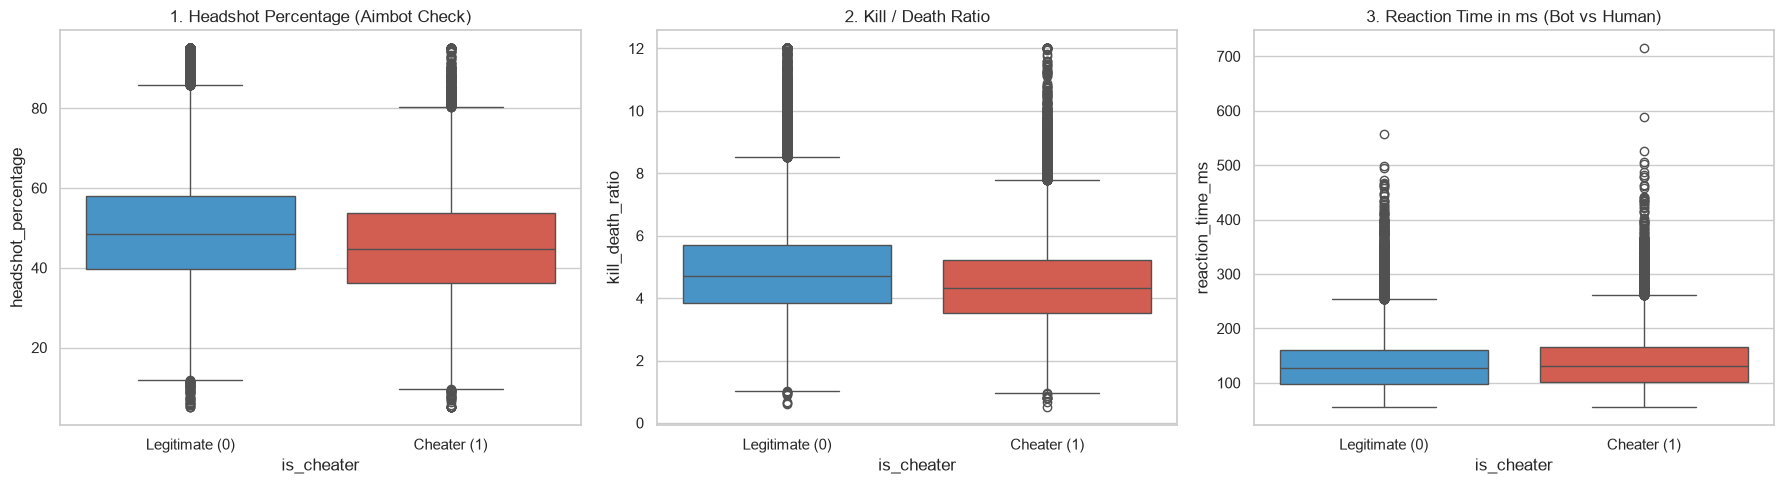

In [33]:
# พล็อตกราฟเปรียบเทียบฟีเจอร์สำคัญระหว่างคนปกติ vs คนโกง
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# กราฟ 1: อัตราการยิงหัว (Headshot Percentage)
sns.boxplot(
    data=labeled_df,
    x="is_cheater",
    y="headshot_percentage",
    ax=axes[0],
    palette=["#3498db", "#e74c3c"],
)
axes[0].set_title("1. Headshot Percentage (Aimbot Check)")
axes[0].set_xticklabels(["Legitimate (0)", "Cheater (1)"])

# กราฟ 2: อัตราส่วน Kill / Death (K/D Ratio)
sns.boxplot(
    data=labeled_df,
    x="is_cheater",
    y="kill_death_ratio",
    ax=axes[1],
    palette=["#3498db", "#e74c3c"],
)
axes[1].set_title("2. Kill / Death Ratio")
axes[1].set_xticklabels(["Legitimate (0)", "Cheater (1)"])

# กราฟ 3: เวลาตอบสนองต่อเป้าหมาย (Reaction Time ms)
sns.boxplot(
    data=labeled_df,
    x="is_cheater",
    y="reaction_time_ms",
    ax=axes[2],
    palette=["#3498db", "#e74c3c"],
)
axes[2].set_title("3. Reaction Time in ms (Bot vs Human)")
axes[2].set_xticklabels(["Legitimate (0)", "Cheater (1)"])

plt.tight_layout()
plt.show()

In [34]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import fbeta_score, precision_score, recall_score


# 1. นิยามฟังก์ชันคำนวณ F2 Score ตามเกณฑ์ของ Kaggle
def calculate_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, zero_division=0)


# 2. ตั้งค่า Stratified 5-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ตัวแปรสำหรับเก็บค่าความน่าจะเป็น (Probability) ของชุด Train และ Test
oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

print(" กำลังเริ่มเทรนโมเดล LightGBM 5-Fold Cross Validation...")

# 3. ลูปเทรนทีละ Fold
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    # กำหนดโมเดล LightGBM Classifier
    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        random_state=42 + fold,
        verbose=-1,
    )

    # สั่ง Fit ข้อมูล พร้อม Early Stopping ป้องกัน Overfitting
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
    )

    # ทำนายความน่าจะเป็นของ Validation Set ประจำ Fold นี้
    val_probs = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_probs

    # ทำนายความน่าจะเป็นของ Test Set แล้วสะสมไว้หาค่าเฉลี่ย
    test_preds += model.predict_proba(X_test)[:, 1] / skf.n_splits

    # ประเมินคะแนน F2 เบื้องต้นของ Fold นี้ที่ Threshold ปกติ (0.5)
    fold_f2 = calculate_f2(y_val, (val_probs >= 0.5).astype(int))
    print(
        f" Fold {fold + 1}/5 เสร็จสิ้น - F2 Score (Default threshold 0.5): {fold_f2:.4f}"
    )

# คำนวณคะแนนรวมทั้ง 5 Fold
baseline_f2 = calculate_f2(y, (oof_preds >= 0.5).astype(int))
print(f"\n คะแนนรวม 5-Fold F2 Score ก่อนจูน: {baseline_f2:.4f}")

 กำลังเริ่มเทรนโมเดล LightGBM 5-Fold Cross Validation...


d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 Fold 1/5 เสร็จสิ้น - F2 Score (Default threshold 0.5): 0.6207


d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 Fold 2/5 เสร็จสิ้น - F2 Score (Default threshold 0.5): 0.6111


d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 Fold 3/5 เสร็จสิ้น - F2 Score (Default threshold 0.5): 0.6092


d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 Fold 4/5 เสร็จสิ้น - F2 Score (Default threshold 0.5): 0.6059


d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 Fold 5/5 เสร็จสิ้น - F2 Score (Default threshold 0.5): 0.6135

 คะแนนรวม 5-Fold F2 Score ก่อนจูน: 0.6121


Optimal Threshold: 0.20
F2 Score improved from 0.6121 to 0.8359 (+0.2238)


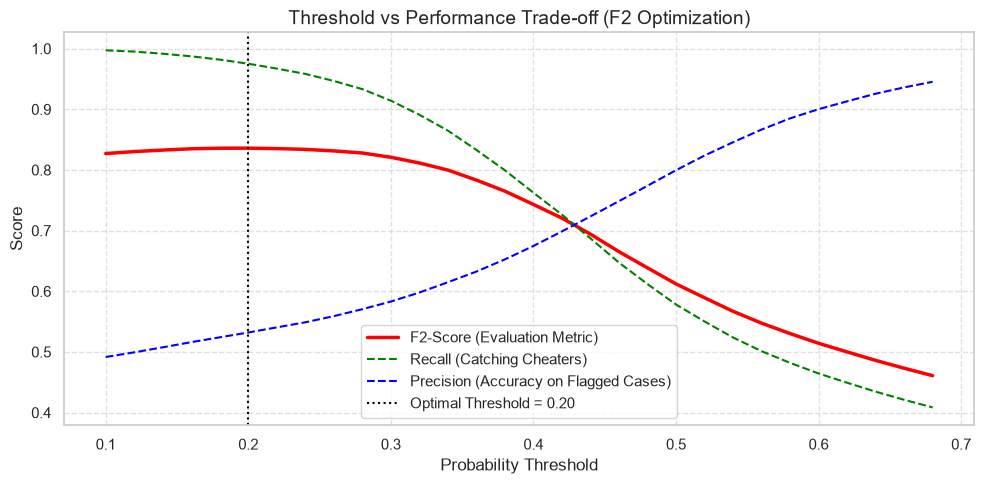

In [35]:
# ค้นหา Threshold ที่ดีที่สุดจากช่วง 0.10 ถึง 0.70
thresholds = np.arange(0.10, 0.70, 0.02)
f2_scores = []
precisions = []
recalls = []

best_thresh = 0.5
best_f2 = 0.0

for t in thresholds:
    preds = (oof_preds >= t).astype(int)
    f2 = calculate_f2(y, preds)
    p = precision_score(y, preds, zero_division=0)
    r = recall_score(y, preds, zero_division=0)

    f2_scores.append(f2)
    precisions.append(p)
    recalls.append(r)

    if f2 > best_f2:
        best_f2 = f2
        best_thresh = t

print(f"Optimal Threshold: {best_thresh:.2f}")
print(
    f"F2 Score improved from {baseline_f2:.4f} to {best_f2:.4f} (+{(best_f2 - baseline_f2):.4f})"
)

# พล็อตกราฟ Threshold vs Metrics (ใช้ภาษาอังกฤษทั้งหมด เพื่อไม่ให้ฟอนต์เพี้ยน)
plt.figure(figsize=(10, 5))
plt.plot(
    thresholds,
    f2_scores,
    label="F2-Score (Evaluation Metric)",
    color="red",
    linewidth=2.5,
)
plt.plot(
    thresholds,
    recalls,
    label="Recall (Catching Cheaters)",
    color="green",
    linestyle="--",
)
plt.plot(
    thresholds,
    precisions,
    label="Precision (Accuracy on Flagged Cases)",
    color="blue",
    linestyle="--",
)
plt.axvline(
    best_thresh,
    color="black",
    linestyle=":",
    label=f"Optimal Threshold = {best_thresh:.2f}",
)

plt.title("Threshold vs Performance Trade-off (F2 Optimization)", fontsize=14)
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [36]:
# โหลด ID ที่ถูกต้องจาก data/sample_submission.csv
sample_sub = pd.read_csv("../data/sample_submission.csv")

# ใช้ Best Threshold ตัดสินว่าผู้เล่นใน Test Set คนไหนเป็นคนโกง (1) หรือคนปกติ (0)
final_task1_pred = (test_preds >= best_thresh).astype(int)

# สร้าง DataFrame ผลลัพธ์
sub_task1 = pd.DataFrame({"id": sample_sub["id"], "task1": final_task1_pred})

# ตรวจสอบความถูกต้อง
assert (
    len(sub_task1) == 25889
), f"จำนวนแถวไม่ครบ! ต้องมี 25889 แถว แต่ได้ {len(sub_task1)}"
assert set(sub_task1["task1"].unique()).issubset(
    {0, 1}
), "ค่าใน task1 ต้องมีแค่ 0 กับ 1 เท่านั้น"
assert sub_task1["task1"].isna().sum() == 0, "พบค่า NaN ในไฟล์ส่งงาน!"

# บันทึกไฟล์ลงโฟลเดอร์ submissions/
os.makedirs("../submissions", exist_ok=True)
sub_task1.to_csv("../submissions/sub_task1.csv", index=False)

print(" ส่งออกไฟล์สำเร็จ!")
print(f"บันทึกไว้ที่: submissions/sub_task1.csv")
print(
    f" สัดส่วนที่ทาย: คนปกติ 0 = {(final_task1_pred == 0).sum():,} คน, คนโกง 1 = {(final_task1_pred == 1).sum():,} คน"
)
sub_task1.head()

 ส่งออกไฟล์สำเร็จ!
บันทึกไว้ที่: submissions/sub_task1.csv
 สัดส่วนที่ทาย: คนปกติ 0 = 10,190 คน, คนโกง 1 = 15,699 คน


,id,task1
0,ANS00001,1
1,ANS00002,1
2,ANS00003,1
3,ANS00004,1
4,ANS00005,0


In [37]:
def create_features(df):
    data = df.copy()

    # 1. Aimbot & Shooting Indicators (ความผิดปกติเรื่องการยิง)
    data["aimbot_index"] = data["headshot_percentage"] * data["crosshair_placement"]
    data["recoil_efficiency"] = data["spray_control_score"] * data["accuracy_score"]
    data["aim_vs_smoothness"] = data["accuracy_score"] / (
        data["aiming_smoothness"] + 1e-4
    )

    # 2. Reaction Speed Anomalies (เวลาตอบสนองเร็วเกินมนุษย์)
    data["reaction_speed_inv"] = 1000.0 / (data["reaction_time_ms"] + 1e-4)
    data["reaction_vs_accuracy"] = data["accuracy_score"] / (
        data["reaction_time_ms"] + 1e-4
    )

    # 3. Smurf & Suspicion Index (ไอดีใหม่แต่สถิติโหดและโดนรีพอร์ตถี่)
    data["suspicion_per_age"] = (
        data["kill_death_ratio"] * data["reports_received"]
    ) / (data["account_age_days"] + 1.0)
    data["kd_per_level"] = data["kill_death_ratio"] / (data["level"] + 1.0)
    data["progression_vs_age"] = data["level_progression_speed"] / (
        data["account_age_days"] + 1.0
    )

    # 4. Combat Efficiency (ความโหดในแมตช์)
    data["damage_per_survival"] = data["damage_per_round"] / (
        data["survival_time_avg"] + 1.0
    )
    data["clutch_vs_game_sense"] = data["clutch_success_rate"] / (
        data["game_sense_score"] + 1e-4
    )

    # 5. Missing Feature Count (จำนวนข้อมูลที่ขาดหาย มักเป็นแพทเทิร์นของบอท)
    data["missing_feature_count"] = data.isnull().sum(axis=1)

    return data


# สร้าง Features ใหม่ให้กับทั้ง Train และ Test
X_fe = create_features(X)
X_test_fe = create_features(X_test)

print(f"Features updated: {X.shape[1]} -> {X_fe.shape[1]} features.")

Features updated: 31 -> 42 features.


In [38]:
# ตัวแปรเก็บค่า Out-of-fold และ Test predictions รอบใหม่
oof_preds_fe = np.zeros(len(X_fe))
test_preds_fe = np.zeros(len(X_test_fe))

print("Starting training with engineered features and tuned hyperparameters...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_fe, y)):
    # แยก Train และ Validation ของแต่ละ Fold ให้ถูกต้อง
    X_train_f, y_train_f = X_fe.iloc[train_idx], y.iloc[train_idx]
    X_val_f, y_val_f = X_fe.iloc[val_idx], y.iloc[val_idx]

    # ปรับจูน Hyperparameters ให้ละเอียดขึ้น และใส่ scale_pos_weight
    model_fe = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=7,
        num_leaves=63,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=1.3,
        random_state=100 + fold,
        verbose=-1,
    )

    model_fe.fit(
        X_train_f,
        y_train_f,
        eval_set=[(X_val_f, y_val_f)],
        callbacks=[lgb.early_stopping(stopping_rounds=40, verbose=False)],
    )

    val_probs = model_fe.predict_proba(X_val_f)[:, 1]
    oof_preds_fe[val_idx] = val_probs
    test_preds_fe += model_fe.predict_proba(X_test_fe)[:, 1] / skf.n_splits

# ค้นหา Best Threshold แบบละเอียด (กวาดทีละ 0.005)
fine_thresholds = np.arange(0.10, 0.45, 0.005)
best_fine_thresh = 0.20
best_fine_f2 = 0.0

for t in fine_thresholds:
    preds = (oof_preds_fe >= t).astype(int)
    score = calculate_f2(y, preds)
    if score > best_fine_f2:
        best_fine_f2 = score
        best_fine_thresh = t

print(f"Previous Best F2: {best_f2:.4f}")
print(f"New Optimal Threshold: {best_fine_thresh:.3f}")
print(
    f"New Best F2 Score: {best_fine_f2:.4f} (Difference: +{(best_fine_f2 - best_f2):.4f})"
)

Starting training with engineered features and tuned hyperparameters...


d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\University\Y3\sem1\cpe342 ml\kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.


Previous Best F2: 0.8359
New Optimal Threshold: 0.245
New Best F2 Score: 0.8365 (Difference: +0.0006)


In [39]:
# ส่งออกไฟล์คำตอบรอบใหม่ที่ได้คะแนนสูงขึ้น
final_task1_pred_fe = (test_preds_fe >= best_fine_thresh).astype(int)

sub_task1_fe = pd.DataFrame({"id": sample_sub["id"], "task1": final_task1_pred_fe})

sub_task1_fe.to_csv("../submissions/sub_task1.csv", index=False)

print("Updated submissions/sub_task1.csv successfully.")
print(f"Total Rows: {len(sub_task1_fe)}")
print(f"Predicted Cheaters (1): {(final_task1_pred_fe == 1).sum():,}")
print(f"Predicted Legitimate (0): {(final_task1_pred_fe == 0).sum():,}")

Updated submissions/sub_task1.csv successfully.
Total Rows: 25889
Predicted Cheaters (1): 15,491
Predicted Legitimate (0): 10,398
